In [1]:
import networkx as nx
import numba as nb
import numpy as np
import seaborn as sns
import sympy as sp
from pprint import pprint
from numba import cfunc, njit
from numbalsoda import lsoda, lsoda_sig

from auxin_signalling_pathway.auxin_signalling_pathway import \
    auxin_signalling_pathway as asp_class


In [2]:
# Generate a simple model with 1 ARF and 1 Aux/IAA
asp_model = asp_class(nARFs=1, nIAAs=1)

# Output default initial conditions and parameters
print('default initial conditions:')
pprint(asp_model.get_default_initial_conditions())

print('\n\nparameter descriptions:')
pprint({key: val[1] for key, val in asp_model.transition_rates.items()})

print('\n\ndefault parameter values:')
pprint(asp_model.get_default_parameters())

default_parameters = asp_model.get_default_parameters()
default_initial_conditions = asp_model.get_default_initial_conditions()

odes, free_vars, param_dict, constraints = asp_model.generate_ode_system()
ode_dict = {var: ode for var, ode in zip(default_initial_conditions, odes)}
pprint(ode_dict)

{'arf__k': (1.0, 'production rate of ARFs'), 'arf__d': (1.0, 'decay rate of ARFs'), 'iaa__k': (1.0, 'production rate of Aux/IAAs'), 'iaa__d': (1.0, 'decay rate of Aux/IAAs'), 'k__D__ARF_1__ARF_1': (0.25, 'Association rate of dimer D__ARF_1__ARF_1'), 'd__D__ARF_1__ARF_1': (0.1, 'Dissociation rate of dimer D__ARF_1__ARF_1'), 'k__D__ARF_1__iaa_1': (0.25, 'Association rate of dimer D__ARF_1__iaa_1'), 'd__D__ARF_1__iaa_1': (0.1, 'Dissociation rate of dimer D__ARF_1__iaa_1'), 'k__D__iaa_1__iaa_1': (0.25, 'Association rate of dimer D__iaa_1__iaa_1'), 'd__D__iaa_1__iaa_1': (0.1, 'Dissociation rate of dimer D__iaa_1__iaa_1'), 'd__iaa_1_x': (0.1, 'rate of auxin-mediated decay of Aux/IAA'), 'k__G__ARF_1__ARF_1': (0.1, 'binding rate for promoter G__ARF_1__ARF_1'), 'd__G__ARF_1__ARF_1': (0.01, 'dissociation rate for promoterG__ARF_1__ARF_1'), 'k__G__ARF_1': (0.1, 'binding rate for promoter G__ARF_1'), 'd__G__ARF_1': (0.01, 'dissociation rate for promoterG__ARF_1'), 'k__G__ARF_1__iaa_1': (0.1, 'bind

{'arf__k': (1.0, 'production rate of ARFs'), 'arf__d': (1.0, 'decay rate of ARFs'), 'iaa__k': (1.0, 'production rate of Aux/IAAs'), 'iaa__d': (1.0, 'decay rate of Aux/IAAs'), 'k__D__ARF_1__ARF_1': (0.25, 'Association rate of dimer D__ARF_1__ARF_1'), 'd__D__ARF_1__ARF_1': (0.1, 'Dissociation rate of dimer D__ARF_1__ARF_1'), 'k__D__ARF_1__iaa_1': (0.25, 'Association rate of dimer D__ARF_1__iaa_1'), 'd__D__ARF_1__iaa_1': (0.1, 'Dissociation rate of dimer D__ARF_1__iaa_1'), 'k__D__iaa_1__iaa_1': (0.25, 'Association rate of dimer D__iaa_1__iaa_1'), 'd__D__iaa_1__iaa_1': (0.1, 'Dissociation rate of dimer D__iaa_1__iaa_1'), 'd__iaa_1_x': (0.1, 'rate of auxin-mediated decay of Aux/IAA'), 'k__G__ARF_1__ARF_1': (0.1, 'binding rate for promoter G__ARF_1__ARF_1'), 'd__G__ARF_1__ARF_1': (0.01, 'dissociation rate for promoterG__ARF_1__ARF_1'), 'k__G__ARF_1': (0.1, 'binding rate for promoter G__ARF_1'), 'd__G__ARF_1': (0.01, 'dissociation rate for promoterG__ARF_1'), 'k__G__ARF_1__iaa_1': (0.1, 'bind

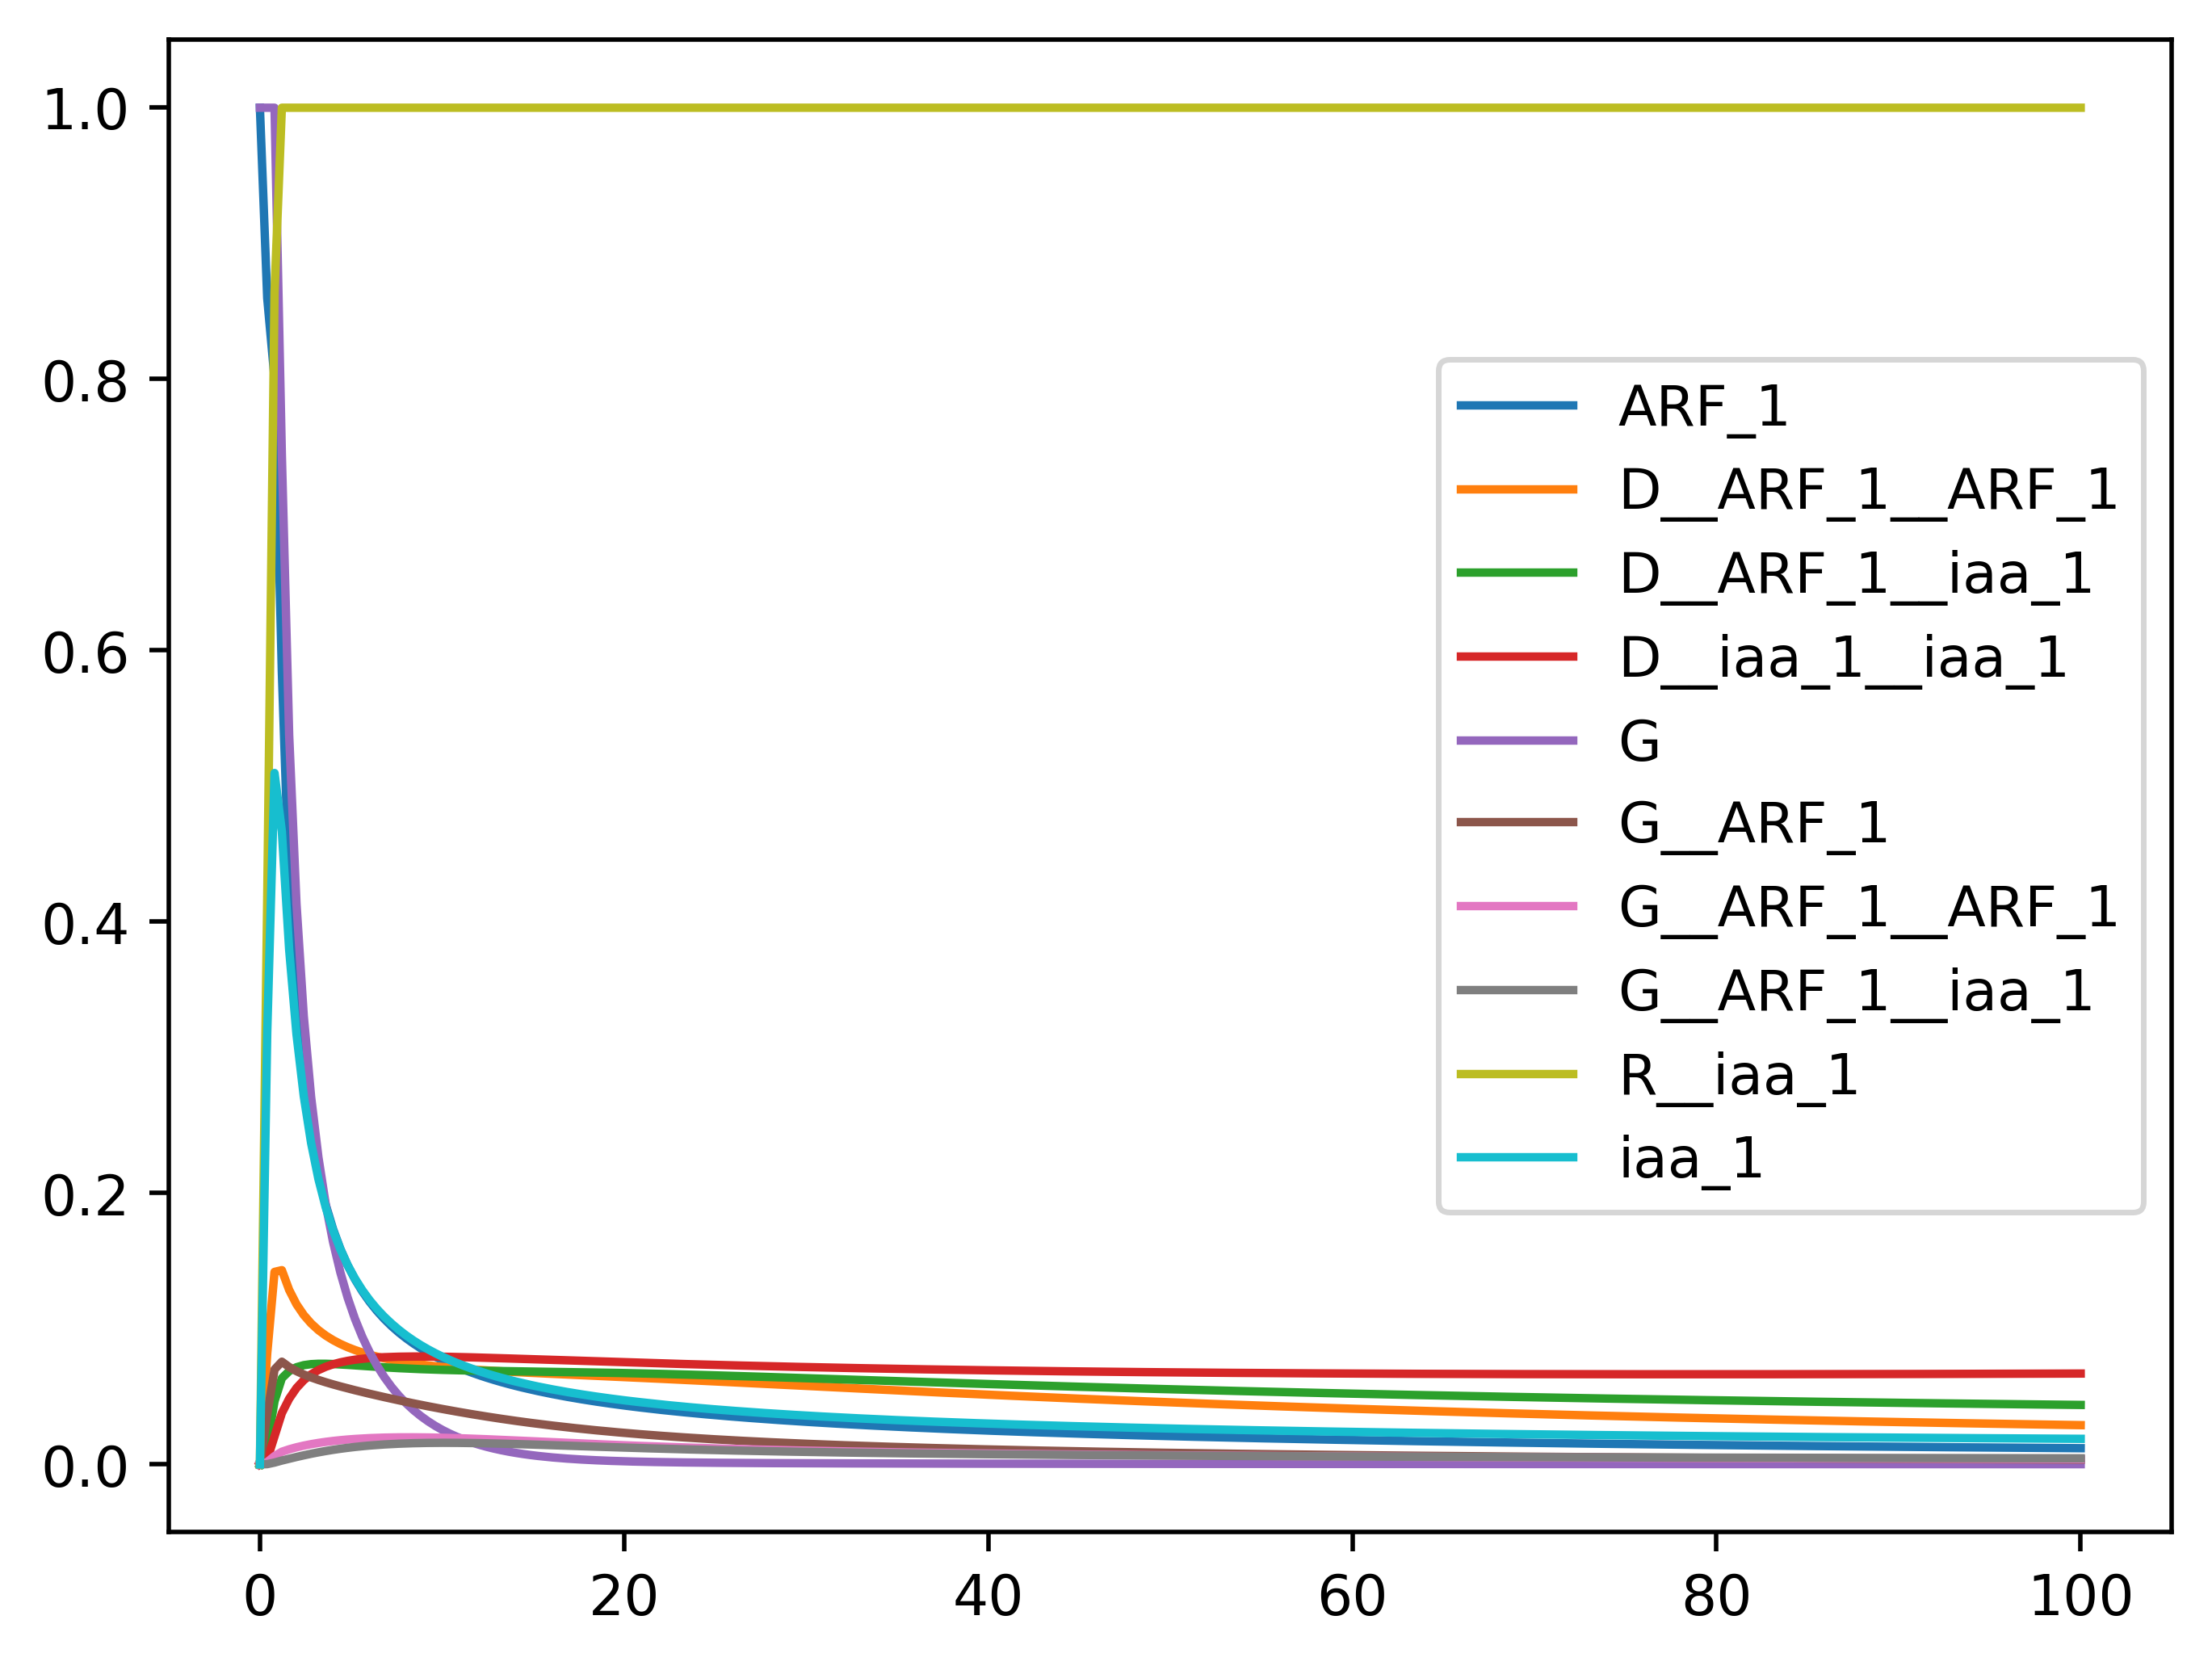

In [3]:
solver = asp_model.make_forward_solver()

ts = np.linspace(0, 100, 250)

aux_level = 1.0
default_output, success = solver(ts, default_parameters,
                            default_initial_conditions,
                            1.0)

import matplotlib.pyplot as plt
plt.plot(ts, default_output / default_output.max(axis=1)[:, None],
         label=list(default_initial_conditions))
plt.legend()
plt.show()

{}


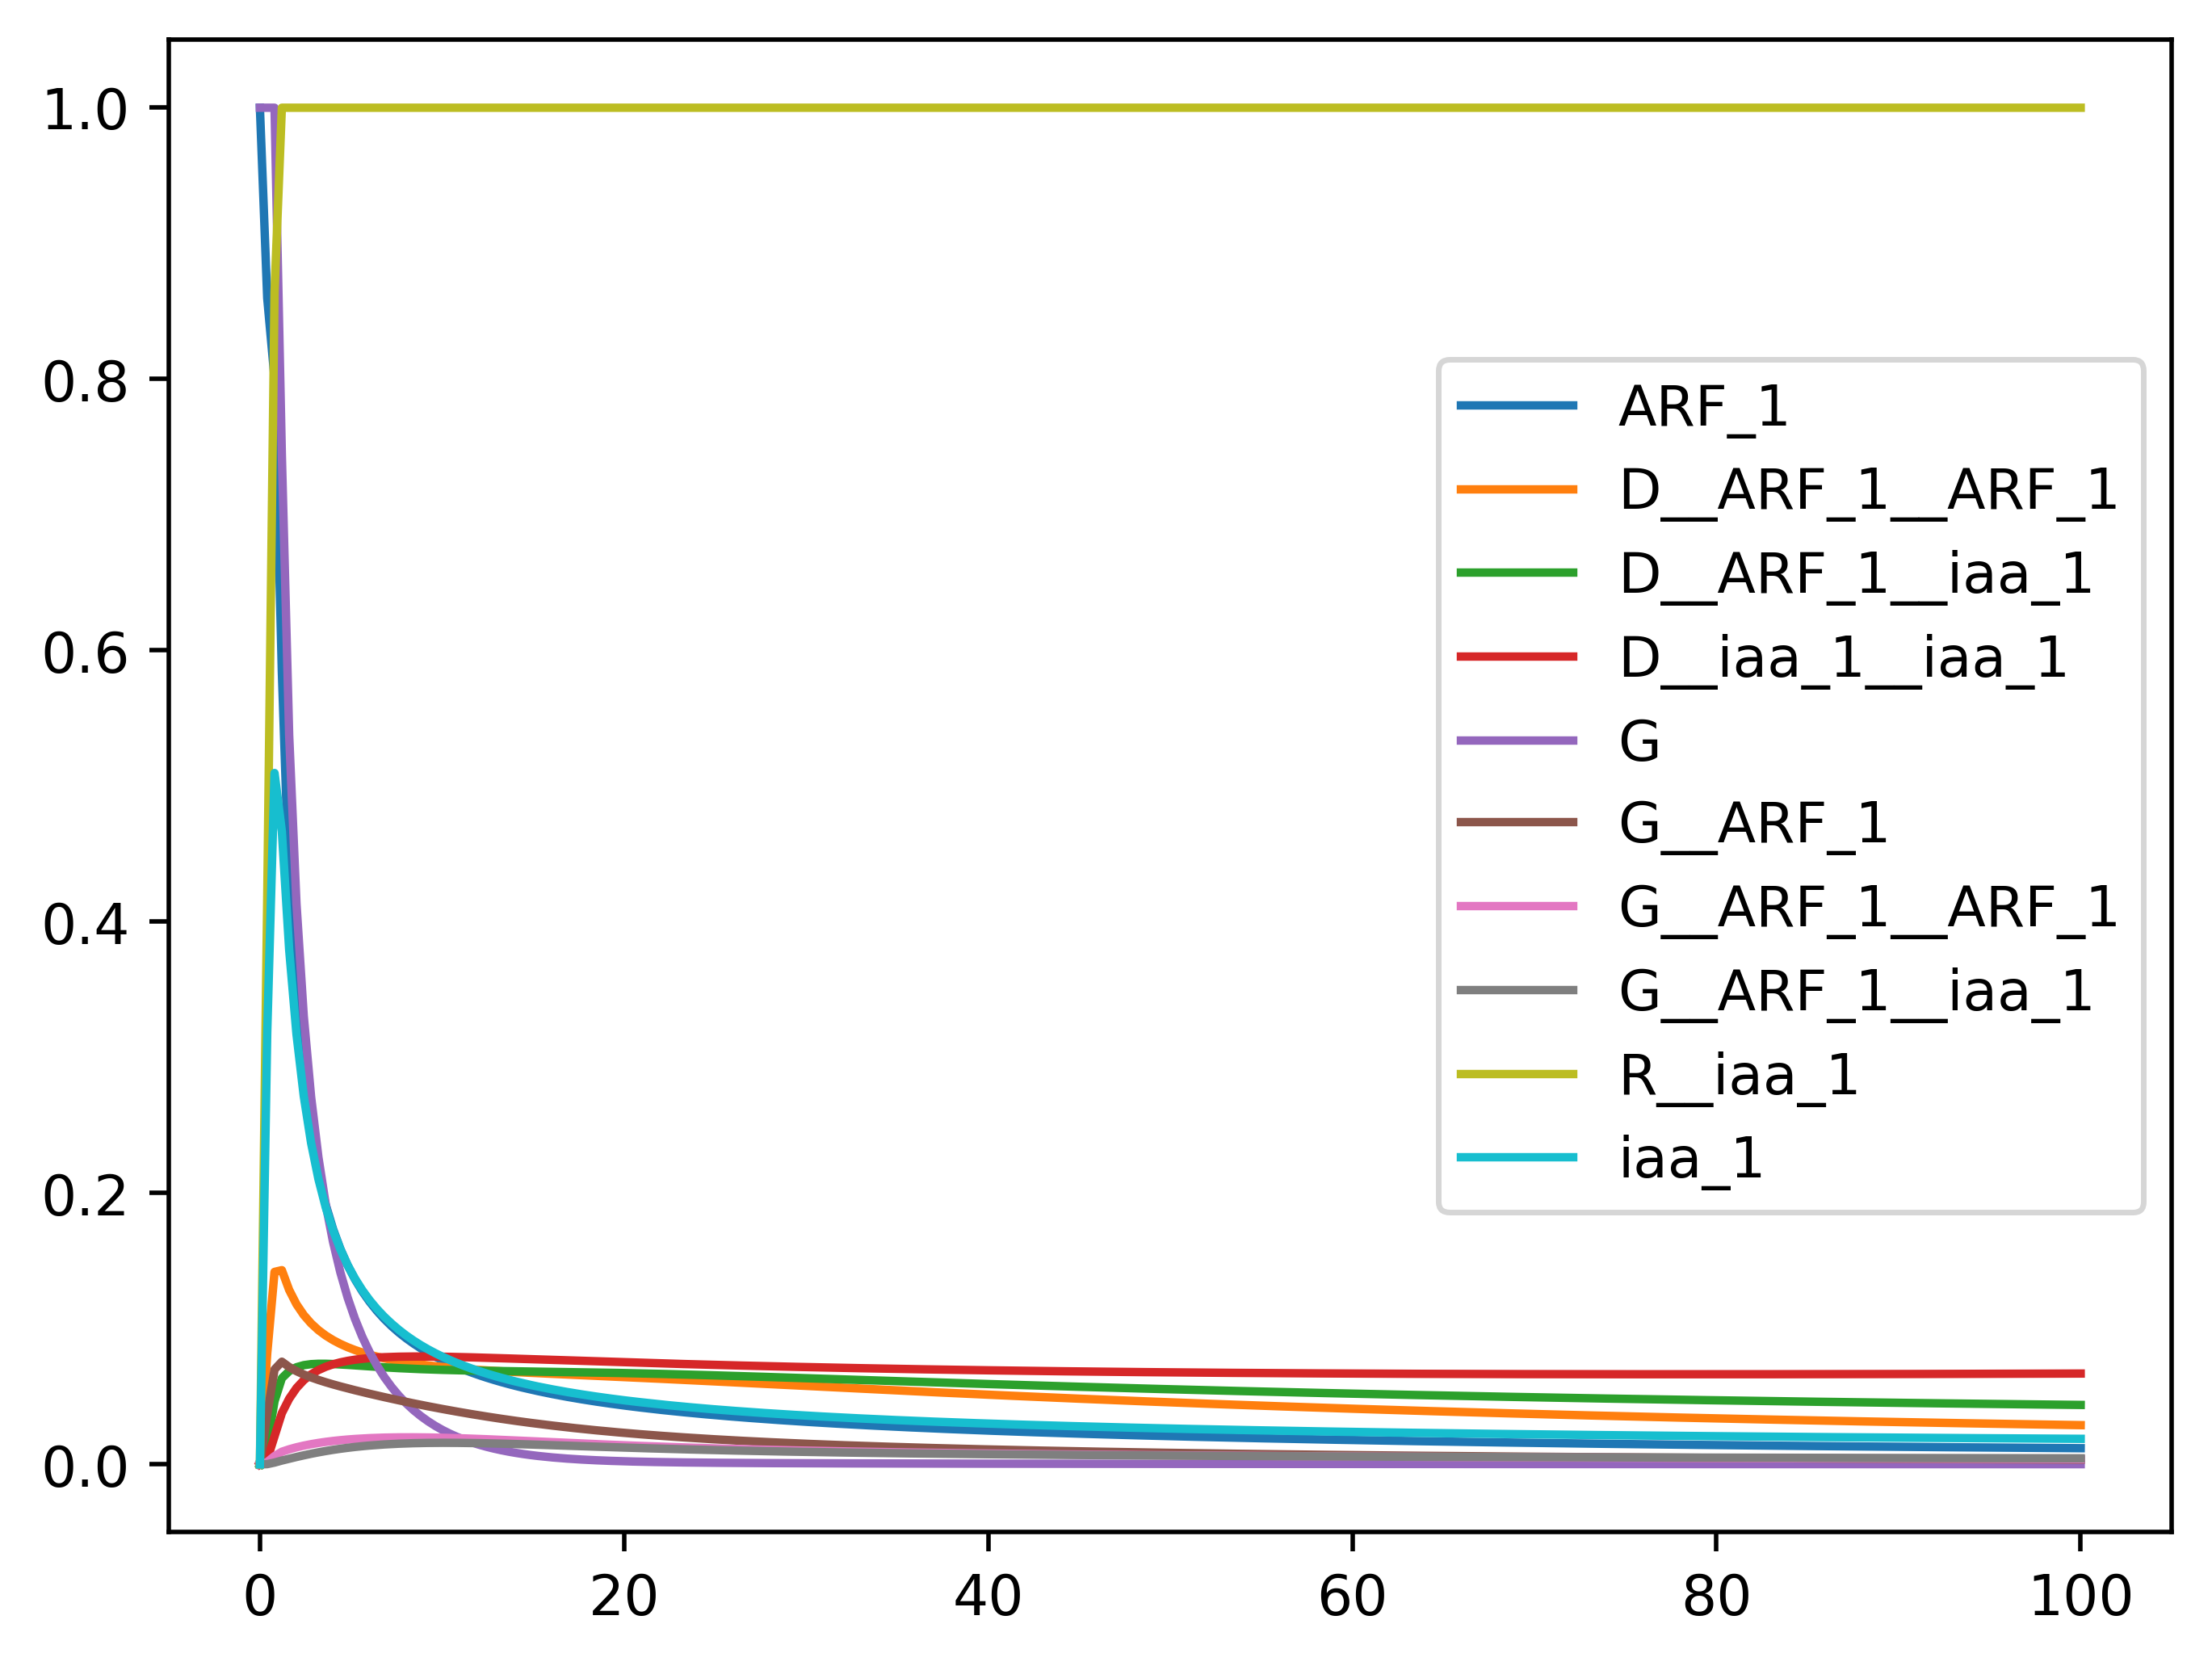

In [9]:
custom_parameters = \
{'arf__d': 1.0,
 'arf__k': 1.0,
 'd__D__ARF_1__ARF_1': 0.1,
 'd__D__ARF_1__iaa_1': 0.1,
 'd__D__iaa_1__iaa_1': 0.1,
 'd__G__ARF_1': 0.01,
 'd__G__ARF_1__ARF_1': 0.01,
 'd__G__ARF_1__ARF_1__unbind__ARF_1': 0.0,
 'd__G__ARF_1__iaa_1': 0.01,
 'd__G__ARF_1__iaa_1__unbind__iaa_1': 0.0,
 'd__R': 0.004166666666666667,
 'd__iaa_1_x': 0.1,
 'iaa__d': 1.0,
 'iaa__k': 1.0,
 'k__D__ARF_1__ARF_1': 0.25,
 'k__D__ARF_1__iaa_1': 0.25,
 'k__D__iaa_1__iaa_1': 0.25,
 'k__G__ARF_1': 0.1,
 'k__G__ARF_1__ARF_1': 0.1,
 'k__G__ARF_1__ARF_1__R__iaa_1': 1.0,
 'k__G__ARF_1__R__iaa_1': 1.0,
 'k__G__ARF_1__bind__ARF_1': 0.0,
 'k__G__ARF_1__bind__iaa_1': 0.0,
 'k__G__ARF_1__iaa_1': 0.1,
 'k__G__ARF_1__iaa_1__R__iaa_1': 1.0,
 'k__G__R__iaa_1': 1.0,
 'k__R': 0.01,
 'k__R__iaa_1__iaa_1': 0.0,
 'k__iaa_1': 0.0}

ts = np.linspace(0, 100, 250)

diff = { k : (custom_parameters[k], default_parameters[k]) for k in list(custom_parameters.keys()) + list(default_parameters.keys())
        if custom_parameters[k] != default_parameters[k]
       }

print(diff)

assert default_parameters == custom_parameters

output, success = solver(ts, custom_parameters,
                            default_initial_conditions,
                            1.0)
plt.plot(ts, output / output.max(axis=1)[:, None], label=list(default_initial_conditions))
plt.legend()
plt.show()